# 02b – Round 2: more training data and four model variants

**What changed compared to round 1 (notebook 02):**
- **Data:** 34 new training areas (deserts, wetlands, cities, farmland, forest, steppe) are added to the 22 round-1
  training areas. Validation and test areas are **unchanged**, so the results are comparable.
- **Models:** four variants, all with Sentinel-1 (VV, VH, VV − VH) as the only input:
  1. U-Net from scratch
  2. U-Net with a ResNet50 encoder pretrained on ImageNet
  3. DeepLabV3+ with the same ResNet50 encoder (atrous convolutions for context at several scales)
  4. SegFormer-B2: a transformer encoder (Mix Transformer) pretrained on ADE20K, with a light MLP decoder

Because round 2 also changes training settings (max. 30 epochs instead of 40, float16 on the GPU),
a **control run** trains the ResNet50 U-Net with exactly the round-2 settings on the **round-1 data only**.
Comparing it with the same model on the full data shows the effect of the extra data alone.

Same rules as before:
- label 255 (no data, snow) is excluded from the loss and from every metric
- normalisation statistics come from the training set only and are saved for the prototype
- the model for the prototype is **selected on validation mIoU**; the test set only reports the result

This notebook does not need Earth Engine. It runs on any GPU machine (university JupyterHub or Kaggle):
- on the JupyterHub, the patch sets must be in `data/` (round 1 in `data/patches_v2`, made by notebook 01c;
  round 2 in `data/patches_v3_extra`, made by notebook 01b)
- on Kaggle, attach the notebook outputs that contain them

Before the long training, a **pre-flight check** builds every model and trains it on one small batch
(a few minutes). A model that fails there (for example because a download is not possible) is skipped,
so no GPU hours are lost on it.

# Preliminaries

In [1]:
import sys
import subprocess
from pathlib import Path

ON_KAGGLE = Path("/kaggle/input").exists()

# keras-hub (for SegFormer) is installed WITHOUT its dependencies: a normal install
# pulls in another TensorFlow version and breaks the existing one.
# The keras-hub version must fit the installed Keras: 0.33.0 needs Keras >= 3.15,
# 0.24.0 works with Keras 3.8 - 3.14 (tested with TensorFlow 2.20 + Keras 3.11.2).
from importlib.metadata import version as package_version, PackageNotFoundError

keras_version = tuple(int(part) for part in package_version("keras").split(".")[:2])
KERAS_HUB = "0.33.0" if keras_version >= (3, 15) else "0.24.0"

try:
    installed = package_version("keras-hub")
except PackageNotFoundError:
    installed = None

if installed != KERAS_HUB:
    print(f"installing keras-hub {KERAS_HUB} (found: {installed}) for Keras {package_version('keras')}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "--force-reinstall",
                    f"keras-hub=={KERAS_HUB}"], check=True)
    if "keras_hub" in sys.modules:
        raise RuntimeError("keras-hub was replaced - restart the kernel and run this cell again")

# small helpers keras-hub needs: downloads from Kaggle Models / Hugging Face (no TensorFlow dependency)
missing = []
for package in ["kagglehub", "huggingface_hub", "regex", "rich"]:
    try:
        package_version(package.replace("_", "-"))
    except PackageNotFoundError:
        missing.append(package)
if missing:
    print("installing", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

import keras_hub
print("keras-hub:", keras_hub.__version__)

installing keras-hub 0.24.0 (found: None) for Keras 3.11.2


installing ['kagglehub']


keras-hub: 0.24.0


In [2]:
import os
import json
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

import tensorflow as tf
import keras
from keras import layers

np.random.seed(14)
tf.random.set_seed(19)
keras.utils.set_random_seed(19)

GPUS = tf.config.list_physical_devices("GPU")
if GPUS:
    # float16 on the GPU: about twice as fast on a Tesla T4, the last layer stays float32
    keras.mixed_precision.set_global_policy("mixed_float16")

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__, "| GPUs:", GPUS)

# record the exact environment of this training run (for the README)
from importlib.metadata import version as package_version
environment = {"python": sys.version.split()[0],
               "gpu": [d.name for d in GPUS],
               "mixed_precision": bool(GPUS)}
for package in ["tensorflow", "keras", "keras-hub", "numpy"]:
    try:
        environment[package] = package_version(package)
    except Exception:
        environment[package] = "not found"
Path("models/round2").mkdir(parents=True, exist_ok=True)
Path("models/round2/environment.json").write_text(json.dumps(environment, indent=2))
print(environment)

TensorFlow: 2.20.0 | Keras: 3.11.2 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
{'python': '3.11.13', 'gpu': ['/physical_device:GPU:0'], 'mixed_precision': True, 'tensorflow': '2.20.0', 'keras': '3.11.2', 'keras-hub': '0.24.0', 'numpy': '2.3.2'}


# Data

The patch sets are found by their `classes.json` (in `data/` or in the attached Kaggle inputs):
- `v2`: round-1 patches (train, validation, test), with the current class scheme (snow ignored)
- `v3_extra`: round-2 patches (train only)

All sets must use exactly the same classes and the same WorldCover mapping.

In [3]:
REQUIRED_VERSIONS = ["v2", "v3_extra"]


def find_patch_sets():
    roots = [Path("data")] + ([Path("/kaggle/input")] if ON_KAGGLE else [])
    found = {}
    for root in roots:
        for folder, _, files in os.walk(root, followlinks=True):
            if "classes.json" in files and any(f.endswith("_x.npy") for f in files):
                info = json.loads((Path(folder) / "classes.json").read_text())
                found.setdefault(info.get("plan_version"), []).append((Path(folder), info))

    for version, copies in found.items():
        if len(copies) > 1:
            raise RuntimeError(f"patch set {version} found {len(copies)} times, attach it only once: "
                               + ", ".join(str(folder) for folder, _ in copies))
    missing = [v for v in REQUIRED_VERSIONS if v not in found]
    if missing:
        raise RuntimeError(f"missing patch sets {missing} – attach the 01 and 01b notebook outputs")
    unexpected = [v for v in found if v not in REQUIRED_VERSIONS]
    if unexpected:
        raise RuntimeError(f"unexpected patch sets {unexpected} – remove these inputs")
    return {version: found[version][0] for version in REQUIRED_VERSIONS}


patch_sets = find_patch_sets()
for version, (folder, _) in patch_sets.items():
    print(f"{version:<10} {folder}")

infos = [info for _, info in patch_sets.values()]
for info in infos[1:]:
    assert info["classes"] == infos[0]["classes"], "patch sets use different classes"
    assert info["worldcover_to_class"] == infos[0]["worldcover_to_class"], "patch sets use different mappings"

CLASSES = infos[0]["classes"]
IGNORE = infos[0]["ignore"]
N_CLASSES = len(CLASSES)
COLORS = ["#006400", "#ffff4c", "#f096ff", "#fa0000", "#b4b4b4", "#0064c8", "#0096a0"]

v2         data/patches_v2
v3_extra   data/patches_v3_extra


In [4]:
data = {}
for split in ["train", "validation", "test"]:
    xs, ys, metas, sources, versions = [], [], [], [], []
    for version, (folder, _) in sorted(patch_sets.items()):
        if not (folder / f"{split}_x.npy").exists():
            continue
        xs.append(np.load(folder / f"{split}_x.npy"))
        ys.append(np.load(folder / f"{split}_y.npy"))
        rows = (folder / f"{split}_meta.csv").read_text().strip().split("\n")[1:]
        metas += [row.split(",") for row in rows]
        sources.append(f"{version}: {len(xs[-1])}")
        versions += [version] * len(xs[-1])
    data[split] = {"x": np.concatenate(xs), "y": np.concatenate(ys), "meta": metas, "version": np.array(versions)}
    print(f"{split:<11} {data[split]['x'].shape}  ({', '.join(sources)})")

    # validation and test must come from round 1 only, otherwise the rounds are not comparable
    if split != "train":
        assert len(sources) == 1 and sources[0].startswith("v2"), f"{split} must come only from v2"

train       (7538, 256, 256, 2)  (v2: 2920, v3_extra: 4618)
validation  (864, 256, 256, 2)  (v2: 864)
test        (864, 256, 256, 2)  (v2: 864)


## Class distribution and class weights

In [5]:
def class_frequency(labels):
    counts = np.bincount(labels[labels != IGNORE].ravel(), minlength=N_CLASSES)
    return counts / counts.sum()


def median_frequency_weights(frequency):
    present = frequency > 0
    weights = np.zeros(N_CLASSES, dtype=np.float32)
    weights[present] = np.median(frequency[present]) / frequency[present]
    return np.clip(weights, 0, 10)


V2_ONLY = np.flatnonzero(data["train"]["version"] == "v2")
frequency = class_frequency(data["train"]["y"])
class_weights = median_frequency_weights(frequency)
class_weights_v2 = median_frequency_weights(class_frequency(data["train"]["y"][V2_ONLY]))

round1 = [24.40, 15.24, 15.91, 36.08, 2.45, 5.42, 0.49]    # training share in round 1 (notebook 01 output)
print(f"{'class':<26}{'round 1 %':>10}{'round 2 %':>10}{'weight':>8}")
for name, r1, f, w in zip(CLASSES, round1, frequency, class_weights):
    print(f"{name:<26}{r1:10.2f}{100 * f:10.2f}{w:8.2f}")

class                      round 1 % round 2 %  weight
Trees (incl. mangroves)        24.40     18.32    0.75
Grassland / shrubland          15.24     15.24    0.90
Cropland                       15.91     13.67    1.00
Built-up                       36.08     31.95    0.43
Bare / sparse vegetation        2.45      6.67    2.05
Permanent water                 5.42      7.19    1.90
Herbaceous wetland              0.49      6.96    1.96


## Normalisation (training data only)

In [6]:
ADD_RATIO = True

sample = data["train"]["x"][:, ::4, ::4, :].astype(np.float32).reshape(-1, 2)
clip_low = np.percentile(sample, 0.5, axis=0)
clip_high = np.percentile(sample, 99.5, axis=0)

sample = np.clip(sample, clip_low, clip_high)
if ADD_RATIO:
    sample = np.concatenate([sample, sample[:, :1] - sample[:, 1:2]], axis=1)
channel_mean = sample.mean(axis=0)
channel_std = sample.std(axis=0)
del sample

# round 2 gets its own folder, so round-1 files are never overwritten
model_folder = Path("models/round2")
model_folder.mkdir(parents=True, exist_ok=True)
normalisation = {
    "channels": ["VV", "VH", "VV-VH"] if ADD_RATIO else ["VV", "VH"],
    "add_ratio": ADD_RATIO,
    "clip_low": clip_low.tolist(),
    "clip_high": clip_high.tolist(),
    "mean": channel_mean.tolist(),
    "std": channel_std.tolist(),
}
(model_folder / "normalisation.json").write_text(json.dumps(normalisation, indent=2))
print(json.dumps(normalisation, indent=2))

{
  "channels": [
    "VV",
    "VH",
    "VV-VH"
  ],
  "add_ratio": true,
  "clip_low": [
    -24.359375,
    -30.578125
  ],
  "clip_high": [
    6.15625,
    -2.798828125
  ],
  "mean": [
    -9.279510498046875,
    -17.078950881958008,
    6.920581340789795
  ],
  "std": [
    5.011114597320557,
    5.170783042907715,
    3.0166337490081787
  ]
}


## Input pipeline

The training patches are now about 2 GB. `tf.data.Dataset.from_tensor_slices` cannot hold arrays
larger than 2 GB, so the dataset only holds patch **numbers**, and each patch is read from the NumPy array when needed.

In [7]:
N_CHANNELS = 3 if ADD_RATIO else 2
BATCH_SIZE = 16


def normalise(x):
    x = tf.clip_by_value(x, clip_low, clip_high)
    if ADD_RATIO:
        x = tf.concat([x, x[..., :1] - x[..., 1:2]], axis=-1)
    return (x - channel_mean) / channel_std


def augment(x, y):
    xy = tf.concat([x, tf.cast(y[..., tf.newaxis], tf.float32)], axis=-1)
    xy = tf.image.random_flip_left_right(xy)
    xy = tf.image.random_flip_up_down(xy)
    xy = tf.image.rot90(xy, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    return xy[..., :-1], tf.cast(xy[..., -1], tf.uint8)


def make_dataset(split, training=False, indices=None):
    x_all, y_all = data[split]["x"], data[split]["y"]
    if indices is None:
        indices = np.arange(len(x_all))
    indices = indices.astype(np.int64)

    def load(i):
        return x_all[i].astype(np.float32), y_all[i]

    def load_tf(i):
        x, y = tf.numpy_function(load, [i], [tf.float32, tf.uint8])
        x.set_shape((256, 256, 2))
        y.set_shape((256, 256))
        return normalise(x), y

    ds = tf.data.Dataset.from_tensor_slices(indices)
    if training:
        ds = ds.shuffle(len(indices), seed=14, reshuffle_each_iteration=True)
    ds = ds.map(load_tf, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset("train", training=True)
train_ds_v2 = make_dataset("train", training=True, indices=V2_ONLY)    # control run: round-1 data only
valid_ds = make_dataset("validation")
test_ds = make_dataset("test")

# Loss and metrics (label 255 ignored)

In [8]:
def make_masked_loss(weights):
    weights_tensor = tf.constant(weights)

    def masked_loss(y_true, y_pred):
        y_true = tf.cast(y_true, tf.int32)
        y_pred = tf.cast(y_pred, tf.float32)
        valid = tf.not_equal(y_true, IGNORE)
        y_safe = tf.where(valid, y_true, 0)

        pixel_loss = keras.losses.sparse_categorical_crossentropy(y_safe, y_pred)
        pixel_weight = tf.gather(weights_tensor, y_safe) * tf.cast(valid, tf.float32)
        return tf.reduce_sum(pixel_loss * pixel_weight) / tf.maximum(tf.reduce_sum(pixel_weight), 1.0)

    return masked_loss


def masked_accuracy(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    valid = tf.not_equal(y_true, IGNORE)
    correct = tf.equal(tf.cast(tf.argmax(y_pred, axis=-1), tf.int32), y_true)
    return tf.reduce_sum(tf.cast(correct & valid, tf.float32)) / tf.maximum(
        tf.reduce_sum(tf.cast(valid, tf.float32)), 1.0)

In [9]:
def predict_split(model, dataset):
    return np.concatenate([np.argmax(model.predict_on_batch(xb), axis=-1) for xb, _ in dataset]).astype(np.uint8)


def confusion(y_true, y_pred):
    valid = y_true != IGNORE
    index = N_CLASSES * y_true[valid].astype(np.int64) + y_pred[valid]
    return np.bincount(index, minlength=N_CLASSES ** 2).reshape(N_CLASSES, N_CLASSES)


def scores(cm):
    # F1 = 2 TP / (actual + predicted): a class that is present but never predicted gets F1 = 0, not NaN
    cm = np.asarray(cm, dtype=np.float64)
    tp = np.diag(cm)
    actual = cm.sum(axis=1)
    predicted = cm.sum(axis=0)
    union = actual + predicted - tp
    iou = np.divide(tp, union, out=np.full(tp.shape, np.nan), where=union > 0)
    f1 = np.divide(2 * tp, actual + predicted, out=np.full(tp.shape, np.nan), where=(actual + predicted) > 0)
    return {
        "oa": tp.sum() / cm.sum() if cm.sum() else np.nan,
        "miou": np.nanmean(iou) if np.any(union > 0) else np.nan,
        "iou": iou,
        "f1": f1,
    }


class ValidationIoU(keras.callbacks.Callback):
    def __init__(self, dataset, y_true):
        super().__init__()
        self.dataset = dataset
        self.y_true = y_true

    def on_epoch_end(self, epoch, logs=None):
        y_pred = predict_split(self.model, self.dataset)
        logs["val_miou"] = scores(confusion(self.y_true, y_pred))["miou"]
        print(f" - val_miou: {logs['val_miou']:.4f}")

# Models

In [10]:
def conv_block(x, filters):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    return x


def classifier(x):
    # softmax in float32, also when the rest of the model runs in float16
    x = layers.Conv2D(N_CLASSES, 1)(x)
    return layers.Activation("softmax", dtype="float32")(x)

### 1. U-Net from scratch (same as round 1)

In [11]:
def build_unet(base_filters=32, dropout=0.3):
    inputs = keras.Input(shape=(256, 256, N_CHANNELS))
    skips = []
    x = inputs
    for level in range(4):
        x = conv_block(x, base_filters * 2 ** level)
        skips.append(x)
        x = layers.MaxPooling2D()(x)

    x = conv_block(x, base_filters * 16)
    x = layers.Dropout(dropout)(x)

    for level in reversed(range(4)):
        x = layers.Conv2DTranspose(base_filters * 2 ** level, 2, strides=2, padding="same")(x)
        x = layers.Concatenate()([x, skips[level]])
        x = conv_block(x, base_filters * 2 ** level)
    return keras.Model(inputs, classifier(x), name="unet_scratch")

### 2. U-Net with ResNet50 encoder (ImageNet), same as round 1

In [12]:
def build_resnet_unet(dropout=0.3):
    encoder = keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=(256, 256, 3))
    skip_names = ["conv1_relu", "conv2_block3_out", "conv3_block4_out", "conv4_block6_out"]
    skips = [encoder.get_layer(name).output for name in skip_names]

    x = encoder.get_layer("conv5_block3_out").output
    x = layers.Dropout(dropout)(x)
    for skip, filters in zip(reversed(skips), [256, 128, 64, 32]):
        x = layers.UpSampling2D()(x)
        x = layers.Concatenate()([x, skip])
        x = conv_block(x, filters)

    x = layers.UpSampling2D()(x)
    x = conv_block(x, 16)
    return keras.Model(encoder.input, classifier(x), name="unet_resnet50")

### 3. DeepLabV3+ with ResNet50 encoder (ImageNet)

The encoder output (16 × 16) goes through **ASPP**: parallel 3 × 3 convolutions with different dilation rates
plus global pooling, so every pixel sees context at several scales. The decoder adds the fine 64 × 64 features
from the encoder and upsamples to 256 × 256. The dilation rates are smaller than in the paper (3, 6, 9 instead of
6, 12, 18) because our feature map is only 16 × 16.

In [13]:
def conv_bn_relu(x, filters, kernel=1, dilation=1):
    x = layers.Conv2D(filters, kernel, padding="same", dilation_rate=dilation, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation("relu")(x)


def build_deeplabv3plus(dropout=0.3):
    encoder = keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=(256, 256, 3))
    high = encoder.get_layer("conv4_block6_out").output      # 16 x 16
    low = encoder.get_layer("conv2_block3_out").output       # 64 x 64

    pooled = layers.GlobalAveragePooling2D(keepdims=True)(high)
    pooled = conv_bn_relu(pooled, 256)
    pooled = layers.UpSampling2D(size=(16, 16), interpolation="bilinear")(pooled)

    branches = [pooled, conv_bn_relu(high, 256)]
    branches += [conv_bn_relu(high, 256, kernel=3, dilation=rate) for rate in (3, 6, 9)]
    x = layers.Concatenate()(branches)
    x = conv_bn_relu(x, 256)
    x = layers.Dropout(dropout)(x)

    x = layers.UpSampling2D(4, interpolation="bilinear")(x)  # 64 x 64
    x = layers.Concatenate()([x, conv_bn_relu(low, 48)])
    x = conv_bn_relu(x, 256, kernel=3)
    x = conv_bn_relu(x, 256, kernel=3)
    x = layers.UpSampling2D(4, interpolation="bilinear")(x)  # 256 x 256
    return keras.Model(encoder.input, classifier(x), name="deeplabv3plus_resnet50")

### 4. SegFormer-B2 (Mix Transformer encoder, pretrained on ADE20K)

The encoder uses self-attention, so it can relate pixels that are far apart. It has no fixed position
embeddings, so the weights trained on 512 × 512 images can be reused for our 256 × 256 patches:
the encoder is rebuilt for 256 × 256 with the same settings and the pretrained weights are copied in.
The SegFormer decoder outputs 1/4 resolution (64 × 64); it is upsampled to 256 × 256.

In [14]:
def pretrained_mit_b2():
    # first choice: the MiT-B2 encoder preset (Kaggle Models)
    # backup: the same encoder taken out of the SegFormer-B2 ADE20K preset on Hugging Face
    loaders = {
        "kaggle mit_b2_ade20k_512": lambda: keras_hub.models.MiTBackbone.from_preset("mit_b2_ade20k_512"),
        "huggingface segformer_b2_ade20k_512": lambda: keras_hub.models.SegFormerBackbone.from_preset(
            "hf://keras/segformer_b2_ade20k_512").image_encoder,
    }
    errors = []
    for source, load in loaders.items():
        try:
            encoder = load()
            print("pretrained MiT-B2 weights from", source)
            return encoder
        except Exception as error:
            errors.append(f"{source}: {type(error).__name__}: {str(error)[:200]}")
    raise RuntimeError("no pretrained MiT-B2 weights could be downloaded -> " + " | ".join(errors))


def build_segformer(dropout=0.1):
    pretrained = pretrained_mit_b2()
    config = pretrained.get_config()
    config["image_shape"] = (256, 256, 3)
    encoder = keras_hub.models.MiTBackbone.from_config(config)
    encoder.set_weights(pretrained.get_weights())

    backbone = keras_hub.models.SegFormerBackbone(image_encoder=encoder, projection_filters=256)
    inputs = keras.Input(shape=(256, 256, N_CHANNELS))
    x = backbone(inputs)                                     # 64 x 64 x 256
    x = layers.Dropout(dropout)(x)
    x = layers.Conv2D(N_CLASSES, 1)(x)
    x = layers.UpSampling2D(4, interpolation="bilinear")(x)
    outputs = layers.Activation("softmax", dtype="float32")(x)
    return keras.Model(inputs, outputs, name="segformer_b2")

# Training

Each variant is trained with the same data, loss, augmentation and callbacks.
If one variant fails (for example a download problem), the error is printed and the next one still runs.

In [15]:
EPOCHS = 30
TIME_BUDGET_HOURS = 10     # Kaggle stops a run after 12 h; no new experiment is started after this

experiments = {
    "unet_resnet50":          {"build": build_resnet_unet,   "optimizer": lambda: keras.optimizers.Adam(1e-4)},
    "deeplabv3plus_resnet50": {"build": build_deeplabv3plus, "optimizer": lambda: keras.optimizers.Adam(1e-4)},
    "segformer_b2":           {"build": build_segformer,
                               "optimizer": lambda: keras.optimizers.AdamW(6e-5, weight_decay=0.01)},
    "unet_scratch":           {"build": build_unet,          "optimizer": lambda: keras.optimizers.Adam(1e-3)},
    # control run: same model and settings as "unet_resnet50", but only the round-1 training data
    "unet_resnet50_v2_only":  {"build": build_resnet_unet,   "optimizer": lambda: keras.optimizers.Adam(1e-4),
                               "train_ds": train_ds_v2, "class_weights": class_weights_v2},
}


def run_experiment(name):
    settings = experiments[name]
    keras.backend.clear_session()
    keras.utils.set_random_seed(19)

    model = settings["build"]()
    loss = make_masked_loss(settings.get("class_weights", class_weights))
    model.compile(optimizer=settings["optimizer"](), loss=loss, metrics=[masked_accuracy])
    print(f"\n{name}: {model.count_params():,} parameters")

    folder = model_folder / name
    folder.mkdir(parents=True, exist_ok=True)
    callbacks = [
        ValidationIoU(valid_ds, data["validation"]["y"]),
        keras.callbacks.ModelCheckpoint(folder / "best.keras", monitor="val_miou", mode="max", save_best_only=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_miou", mode="max", factor=0.5, patience=3),
        keras.callbacks.EarlyStopping(monitor="val_miou", mode="max", patience=8),
        keras.callbacks.CSVLogger(folder / "history.csv"),
    ]

    start = time.time()
    history = model.fit(settings.get("train_ds", train_ds), validation_data=valid_ds, epochs=EPOCHS, callbacks=callbacks)
    history = {key: [float(v) for v in values] for key, values in history.history.items()}
    history["minutes"] = (time.time() - start) / 60
    history["parameters"] = model.count_params()
    (folder / "history.json").write_text(json.dumps(history, indent=2))
    print(f"{name}: {history['minutes']:.0f} minutes, best val mIoU {max(history['val_miou']):.4f}")

## Pre-flight check (a few minutes)

Every model is built (this also downloads the pretrained weights), trained on one full batch
(same batch size as in training, so a GPU memory problem also shows up here), saved, reloaded and checked. A model that fails here is removed from the run, so the long training
does not stop hours later because of it.

In [16]:
check_x, check_y = next(iter(valid_ds))          # one full batch of BATCH_SIZE patches
n_check = int(check_x.shape[0])
preflight_failed = {}

for name, settings in list(experiments.items()):
    start = time.time()
    model = None
    try:
        keras.backend.clear_session()
        model = settings["build"]()
        model.compile(optimizer=settings["optimizer"](), loss=make_masked_loss(class_weights),
                      metrics=[masked_accuracy])
        loss_value = float(np.ravel(model.train_on_batch(check_x, check_y))[0])
        probabilities = np.asarray(model.predict_on_batch(check_x))
        assert probabilities.shape == (n_check, 256, 256, N_CLASSES), f"wrong output shape {probabilities.shape}"
        assert np.isfinite(probabilities).all() and np.isfinite(loss_value), "NaN in output or loss"

        path = model_folder / "preflight_check.keras"
        model.save(path)
        reloaded = np.asarray(keras.models.load_model(path, compile=False).predict_on_batch(check_x))
        path.unlink()
        assert np.allclose(probabilities, reloaded, atol=1e-2), "reloaded model predicts differently"
        print(f"OK    {name:<24}{model.count_params() / 1e6:6.1f}M parameters  loss {loss_value:.3f}  "
              f"({time.time() - start:.0f} s)")
    except Exception as error:
        preflight_failed[name] = f"{type(error).__name__}: {error}"
        print(f"FAIL  {name:<24}{preflight_failed[name][:400]}")
        if "ResourceExhausted" in type(error).__name__ or "OOM" in str(error):
            print("      -> not enough GPU memory: set BATCH_SIZE = 8 in the input pipeline cell and run again")
    finally:
        model = None
        keras.backend.clear_session()

for name in preflight_failed:
    experiments.pop(name)
print("\nmodels for the training run:", list(experiments))
if preflight_failed:
    print("!!! skipped after the pre-flight check:", list(preflight_failed))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


OK    unet_resnet50             32.6M parameters  loss 2.114  (54 s)
OK    deeplabv3plus_resnet50    17.8M parameters  loss 2.731  (41 s)


100%|██████████| 978/978 [00:00<00:00, 3.11MB/s]


100%|██████████| 93.0M/93.0M [00:03<00:00, 25.7MB/s]


pretrained MiT-B2 weights from kaggle mit_b2_ade20k_512


OK    segformer_b2              24.7M parameters  loss 2.274  (159 s)
OK    unet_scratch               7.8M parameters  loss 2.470  (24 s)
OK    unet_resnet50_v2_only     32.6M parameters  loss 2.620  (44 s)

models for the training run: ['unet_resnet50', 'deeplabv3plus_resnet50', 'segformer_b2', 'unet_scratch', 'unet_resnet50_v2_only']


## Training run

In [17]:
finished = []
run_start = time.time()
for name in experiments:
    if (time.time() - run_start) / 3600 > TIME_BUDGET_HOURS:
        print(f"\n!!! time budget reached, {name} is skipped")
        continue
    try:
        run_experiment(name)
        finished.append(name)
    except Exception as error:
        print(f"\n!!! {name} failed: {type(error).__name__}: {error}")

print("\nFinished:", finished)
if preflight_failed:
    print("Skipped in the pre-flight check:", list(preflight_failed))


unet_resnet50: 32,602,743 parameters
Epoch 1/30
472/472 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - loss: 1.5283 - masked_accuracy: 0.3511 - val_miou: 0.0017
472/472 ━━━━━━━━━━━━━━━━━━━━ 106s 154ms/step - loss: 1.3207 - masked_accuracy: 0.4475 - val_loss: 2.9663 - val_masked_accuracy: 0.0023 - val_miou: 0.0017 - learning_rate: 1.0000e-04
Epoch 2/30
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - loss: 1.0693 - masked_accuracy: 0.6501 - val_miou: 0.2870
472/472 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 1.0434 - masked_accuracy: 0.6638 - val_loss: 1.2961 - val_masked_accuracy: 0.5385 - val_miou: 0.2870 - learning_rate: 1.0000e-04
Epoch 3/30
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - loss: 0.9437 - masked_accuracy: 0.7002 - val_miou: 0.3201
472/472 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.9325 - masked_accuracy: 0.7017 - val_loss: 1.2463 - val_masked_accuracy: 0.5535 - val_miou: 0.3201 - learning_rate: 1.0000e-04
Epoch 4/30
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - loss: 0.8716 - masked_a

472/472 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - loss: 1.1136 - masked_accuracy: 0.6007 - val_miou: 0.0031
472/472 ━━━━━━━━━━━━━━━━━━━━ 114s 182ms/step - loss: 0.9153 - masked_accuracy: 0.6669 - val_loss: 22.4044 - val_masked_accuracy: 0.0177 - val_miou: 0.0031 - learning_rate: 1.0000e-04
Epoch 2/30
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - loss: 0.7329 - masked_accuracy: 0.7236 - val_miou: 0.2869
472/472 ━━━━━━━━━━━━━━━━━━━━ 67s 141ms/step - loss: 0.7105 - masked_accuracy: 0.7285 - val_loss: 1.1612 - val_masked_accuracy: 0.5202 - val_miou: 0.2869 - learning_rate: 1.0000e-04
Epoch 3/30
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step - loss: 0.6589 - masked_accuracy: 0.7462 - val_miou: 0.3322
472/472 ━━━━━━━━━━━━━━━━━━━━ 85s 180ms/step - loss: 0.6547 - masked_accuracy: 0.7465 - val_loss: 1.0810 - val_masked_accuracy: 0.5873 - val_miou: 0.3322 - learning_rate: 1.0000e-04
Epoch 4/30
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step - loss: 0.6189 - masked_accuracy: 0.7563 - val_miou: 0.3286
472/472 ━━

472/472 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step - loss: 1.1357 - masked_accuracy: 0.5919 - val_miou: 0.3260
472/472 ━━━━━━━━━━━━━━━━━━━━ 260s 307ms/step - loss: 0.8895 - masked_accuracy: 0.6788 - val_loss: 1.1226 - val_masked_accuracy: 0.5781 - val_miou: 0.3260 - learning_rate: 6.0000e-05
Epoch 2/30
472/472 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - loss: 0.6564 - masked_accuracy: 0.7509 - val_miou: 0.3306
472/472 ━━━━━━━━━━━━━━━━━━━━ 50s 105ms/step - loss: 0.6407 - masked_accuracy: 0.7568 - val_loss: 1.0966 - val_masked_accuracy: 0.5988 - val_miou: 0.3306 - learning_rate: 6.0000e-05
Epoch 3/30
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - loss: 0.5822 - masked_accuracy: 0.7724 - val_miou: 0.3386
472/472 ━━━━━━━━━━━━━━━━━━━━ 50s 105ms/step - loss: 0.5780 - masked_accuracy: 0.7745 - val_loss: 1.1080 - val_masked_accuracy: 0.6027 - val_miou: 0.3386 - learning_rate: 6.0000e-05
Epoch 4/30
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - loss: 0.5528 - masked_accuracy: 0.7823 - val_miou: 0.3303
472/472 ━━━━━━

472/472 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - loss: 1.4653 - masked_accuracy: 0.4994 - val_miou: 0.2443
472/472 ━━━━━━━━━━━━━━━━━━━━ 64s 112ms/step - loss: 1.3756 - masked_accuracy: 0.5231 - val_loss: 1.3347 - val_masked_accuracy: 0.5139 - val_miou: 0.2443 - learning_rate: 0.0010
Epoch 2/30
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - loss: 1.2579 - masked_accuracy: 0.5409 - val_miou: 0.2712
472/472 ━━━━━━━━━━━━━━━━━━━━ 42s 89ms/step - loss: 1.2145 - masked_accuracy: 0.5560 - val_loss: 1.3047 - val_masked_accuracy: 0.5199 - val_miou: 0.2712 - learning_rate: 0.0010
Epoch 3/30
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - loss: 1.1328 - masked_accuracy: 0.5853 - val_miou: 0.2165
472/472 ━━━━━━━━━━━━━━━━━━━━ 41s 86ms/step - loss: 1.1136 - masked_accuracy: 0.5919 - val_loss: 1.6924 - val_masked_accuracy: 0.4521 - val_miou: 0.2165 - learning_rate: 0.0010
Epoch 4/30
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - loss: 1.0543 - masked_accuracy: 0.6125 - val_miou: 0.2353
472/472 ━━━━━━━━━━━━━━━━━━━━ 4

# Training performance

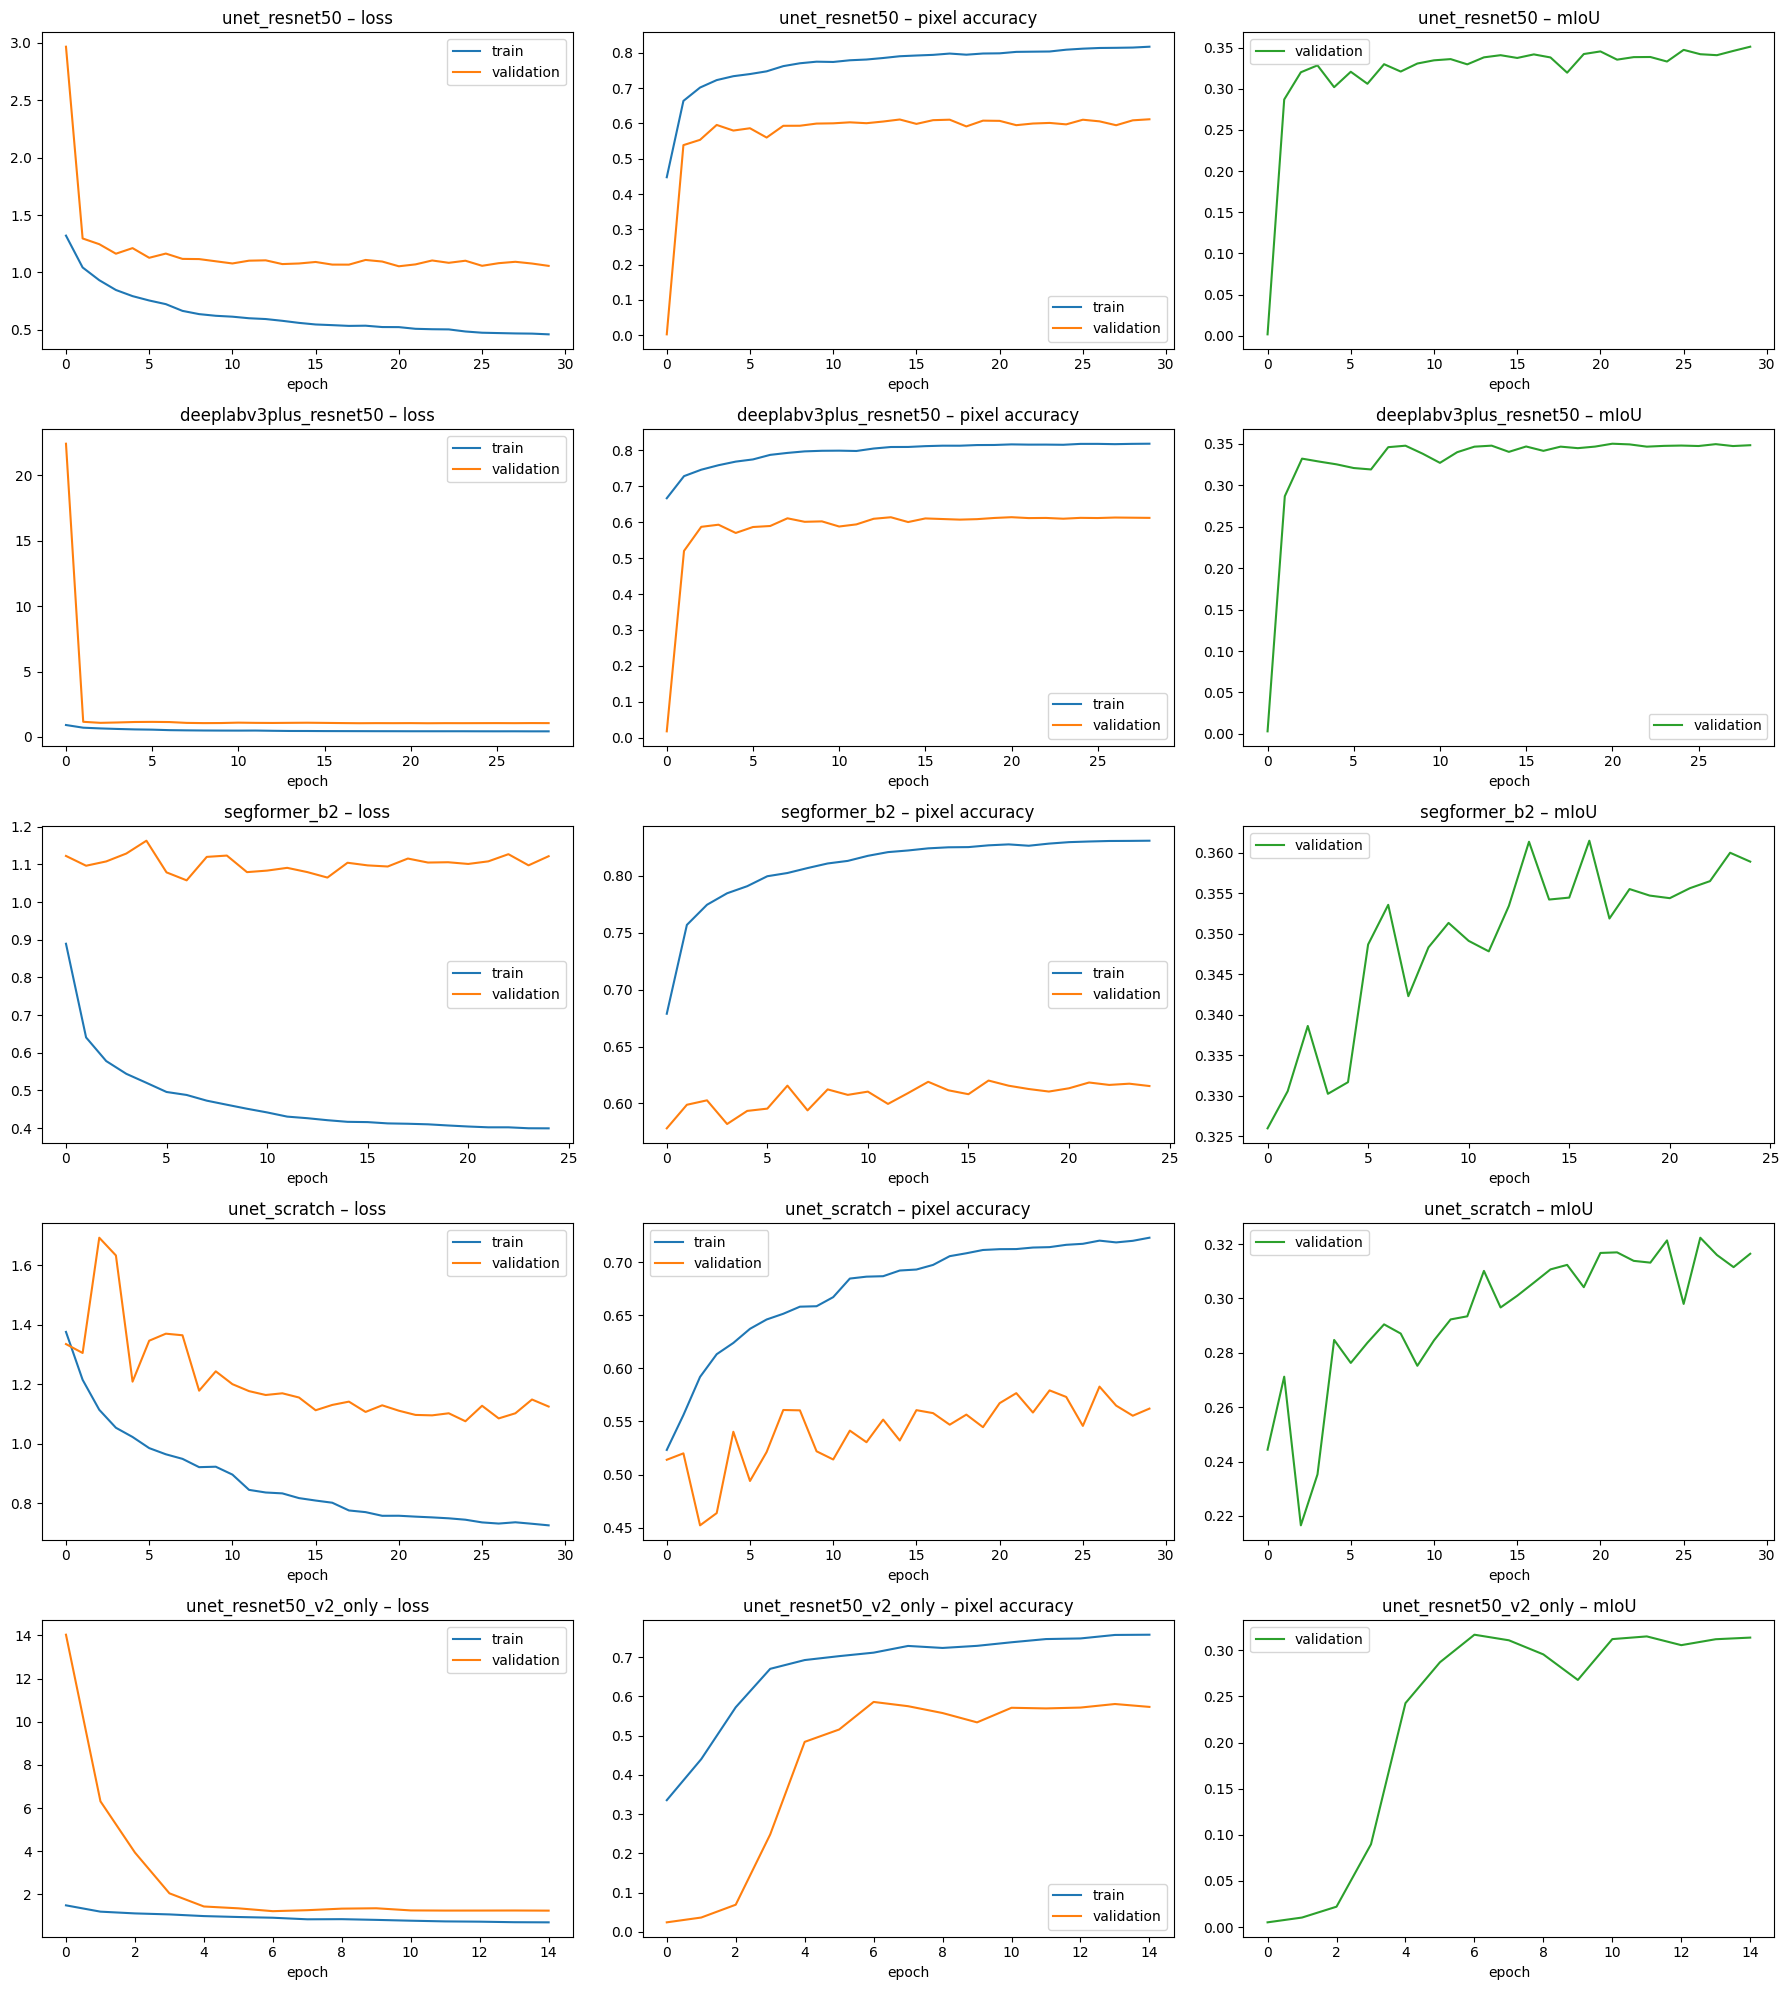

In [18]:
fig, axes = plt.subplots(len(finished), 3, figsize=(18, 4 * len(finished)), squeeze=False)
for row, name in enumerate(finished):
    history = json.loads((model_folder / name / "history.json").read_text())
    axes[row, 0].plot(history["loss"], label="train")
    axes[row, 0].plot(history["val_loss"], label="validation")
    axes[row, 0].set_title(f"{name} – loss")
    axes[row, 1].plot(history["masked_accuracy"], label="train")
    axes[row, 1].plot(history["val_masked_accuracy"], label="validation")
    axes[row, 1].set_title(f"{name} – pixel accuracy")
    axes[row, 2].plot(history["val_miou"], color="tab:green", label="validation")
    axes[row, 2].set_title(f"{name} – mIoU")
    for ax in axes[row]:
        ax.set_xlabel("epoch")
        ax.legend()
plt.tight_layout()
plt.show()

# Comparison

The model for the prototype is **selected on validation mIoU**. Test results are shown for all variants
so they can be compared in the report, but they are not used for the choice.
Round-1 numbers (notebook 02) are added as reference.

In [19]:
def load_trained(name):
    return keras.models.load_model(model_folder / name / "best.keras", compile=False)


results = {}
for name in finished:
    model = load_trained(name)
    history = json.loads((model_folder / name / "history.json").read_text())

    start = time.time()
    valid_pred = predict_split(model, valid_ds)
    seconds_per_patch = (time.time() - start) / len(valid_pred)

    results[name] = {
        "valid": scores(confusion(data["validation"]["y"], valid_pred)),
        "test_pred": predict_split(model, test_ds),
        "parameters": history["parameters"],
        "minutes": history["minutes"],
        "epochs": len(history["loss"]),
        "ms_per_patch": 1000 * seconds_per_patch,
    }
    results[name]["test"] = scores(confusion(data["test"]["y"], results[name]["test_pred"]))

# the control run only answers "does more data help?", it is not a candidate for the prototype
candidates = [name for name in results if not name.endswith("_v2_only")]
best_name = max(candidates, key=lambda name: results[name]["valid"]["miou"])

print(f"{'model':<24}{'params':>12}{'epochs':>8}{'min':>6}{'ms/patch':>10}{'val OA':>8}{'val mIoU':>10}{'test OA':>9}{'test mIoU':>11}")
print(f"{'round 1: unet_scratch':<24}{'7.8M':>12}{17:>8}{'':>6}{'':>10}{0.576:8.3f}{0.317:10.3f}{'-':>9}{'-':>11}")
print(f"{'round 1: unet_resnet50':<24}{'32.6M':>12}{28:>8}{'':>6}{'':>10}{0.583:8.3f}{0.324:10.3f}{0.642:9.3f}{0.374:11.3f}")
for name, r in results.items():
    mark = "  <- selected" if name == best_name else ("  (control: round-1 data)" if name.endswith("_v2_only") else "")
    print(f"{name:<24}{r['parameters'] / 1e6:11.1f}M{r['epochs']:8d}{r['minutes']:6.0f}{r['ms_per_patch']:10.1f}"
          f"{r['valid']['oa']:8.3f}{r['valid']['miou']:10.3f}{r['test']['oa']:9.3f}{r['test']['miou']:11.3f}{mark}")

model                         params  epochs   min  ms/patch  val OA  val mIoU  test OA  test mIoU
round 1: unet_scratch           7.8M      17                   0.576     0.317        -          -
round 1: unet_resnet50         32.6M      28                   0.583     0.324    0.642      0.374
unet_resnet50                  32.6M      30    25       5.5   0.612     0.351    0.669      0.399
deeplabv3plus_resnet50         17.8M      29    33       6.4   0.614     0.350    0.673      0.401
segformer_b2                   24.7M      25    23      14.7   0.620     0.361    0.691      0.426  <- selected
unet_scratch                    7.8M      30    21       3.6   0.583     0.322    0.630      0.339
unet_resnet50_v2_only          32.6M      15     7       5.6   0.586     0.317    0.622      0.349  (control: round-1 data)


In [20]:
print("Validation IoU per class")
print(f"{'class':<26}" + "".join(f"{name[:14]:>16}" for name in results))
for i, class_name in enumerate(CLASSES):
    print(f"{class_name:<26}" + "".join(f"{results[name]['valid']['iou'][i]:16.3f}" for name in results))

print("\nTest IoU per class")
print(f"{'class':<26}" + "".join(f"{name[:14]:>16}" for name in results))
for i, class_name in enumerate(CLASSES):
    print(f"{class_name:<26}" + "".join(f"{results[name]['test']['iou'][i]:16.3f}" for name in results))

Validation IoU per class
class                        unet_resnet50  deeplabv3plus_    segformer_b2    unet_scratch  unet_resnet50_
Trees (incl. mangroves)              0.472           0.486           0.502           0.447           0.429
Grassland / shrubland                0.417           0.410           0.409           0.390           0.408
Cropland                             0.295           0.314           0.287           0.283           0.264
Built-up                             0.550           0.532           0.562           0.527           0.540
Bare / sparse vegetation             0.100           0.098           0.135           0.098           0.088
Permanent water                      0.617           0.607           0.634           0.512           0.484
Herbaceous wetland                   0.008           0.005           0.002           0.000           0.005

Test IoU per class
class                        unet_resnet50  deeplabv3plus_    segformer_b2    unet_scratch  unet_re

In [21]:
if "unet_resnet50" in results and "unet_resnet50_v2_only" in results:
    full, control = results["unet_resnet50"], results["unet_resnet50_v2_only"]
    print("Effect of the extra training data (same model, same settings):")
    print(f"  validation mIoU: {control['valid']['miou']:.3f} -> {full['valid']['miou']:.3f} "
          f"({full['valid']['miou'] - control['valid']['miou']:+.3f})")
    for k, name in enumerate(CLASSES):
        print(f"  {name:<26} IoU {control['valid']['iou'][k]:.3f} -> {full['valid']['iou'][k]:.3f}")

Effect of the extra training data (same model, same settings):
  validation mIoU: 0.317 -> 0.351 (+0.034)
  Trees (incl. mangroves)    IoU 0.429 -> 0.472
  Grassland / shrubland      IoU 0.408 -> 0.417
  Cropland                   IoU 0.264 -> 0.295
  Built-up                   IoU 0.540 -> 0.550
  Bare / sparse vegetation   IoU 0.088 -> 0.100
  Permanent water            IoU 0.484 -> 0.617
  Herbaceous wetland         IoU 0.005 -> 0.008


# Selected model on the test set

Selected: segformer_b2
Test OA:   0.691
Test mIoU: 0.426

class                          IoU      F1      pixels
Trees (incl. mangroves)      0.464   0.634  15,075,436
Grassland / shrubland        0.424   0.595   8,908,324
Cropland                     0.595   0.746  10,277,548
Built-up                     0.615   0.761  19,362,908
Bare / sparse vegetation     0.080   0.149     576,284
Permanent water              0.778   0.875   2,360,180
Herbaceous wetland           0.028   0.054      62,424


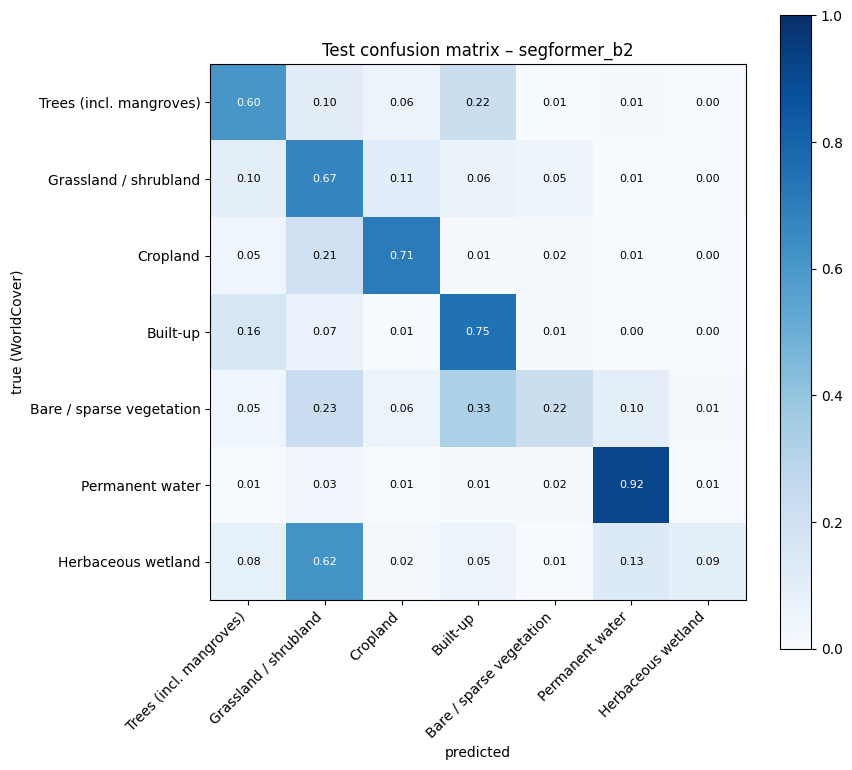

In [22]:
test_pred = results[best_name]["test_pred"]
test_cm = confusion(data["test"]["y"], test_pred)
test_result = results[best_name]["test"]

print(f"Selected: {best_name}")
print(f"Test OA:   {test_result['oa']:.3f}")
print(f"Test mIoU: {test_result['miou']:.3f}\n")
print(f"{'class':<26}{'IoU':>8}{'F1':>8}{'pixels':>12}")
for i, name in enumerate(CLASSES):
    print(f"{name:<26}{test_result['iou'][i]:8.3f}{test_result['f1'][i]:8.3f}{test_cm[i].sum():12,}")

row_sums = test_cm.sum(axis=1, keepdims=True)
cm_normalised = np.divide(test_cm, row_sums, out=np.zeros(test_cm.shape), where=row_sums > 0)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm_normalised, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(N_CLASSES), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(N_CLASSES), CLASSES)
ax.set_xlabel("predicted")
ax.set_ylabel("true (WorldCover)")
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        ax.text(j, i, f"{cm_normalised[i, j]:.2f}", ha="center", va="center",
                color="white" if cm_normalised[i, j] > 0.5 else "black", fontsize=8)
fig.colorbar(im)
ax.set_title(f"Test confusion matrix – {best_name}")
plt.tight_layout()
plt.show()

In [23]:
test_meta = data["test"]["meta"]
test_areas = sorted({row[0] for row in test_meta})
test_months = sorted({int(row[2]) for row in test_meta})

print(f"{'area':<16}{'continent':<16}" + "".join(f"{name[:12]:>14}" for name in results))
for area in test_areas:
    idx = [i for i, row in enumerate(test_meta) if row[0] == area]
    line = f"{area:<16}{test_meta[idx[0]][1]:<16}"
    for name in results:
        line += f"{scores(confusion(data['test']['y'][idx], results[name]['test_pred'][idx]))['miou']:14.3f}"
    print(line)

print(f"\n{'month':<8}" + "".join(f"{name[:12]:>14}" for name in results))
for month in test_months:
    idx = [i for i, row in enumerate(test_meta) if int(row[2]) == month]
    line = f"{month:<8}"
    for name in results:
        line += f"{scores(confusion(data['test']['y'][idx], results[name]['test_pred'][idx]))['miou']:14.3f}"
    print(line)

area            continent         unet_resnet5  deeplabv3plu  segformer_b2  unet_scratch  unet_resnet5
Christchurch    Oceania                  0.330         0.337         0.363         0.284         0.303
Cordoba_edge    South America            0.324         0.321         0.383         0.269         0.264
Hanoi_edge      Asia                     0.337         0.338         0.340         0.310         0.309
Portland_edge   North America            0.351         0.347         0.352         0.302         0.276
Pretoria_edge   Africa                   0.270         0.274         0.280         0.243         0.236
Toulouse        Europe                   0.379         0.369         0.388         0.346         0.311

month     unet_resnet5  deeplabv3plu  segformer_b2  unet_scratch  unet_resnet5
1                0.409         0.408         0.430         0.348         0.358
4                0.412         0.417         0.431         0.358         0.369
7                0.383         0.384     

## Best and worst test patches (selected model)

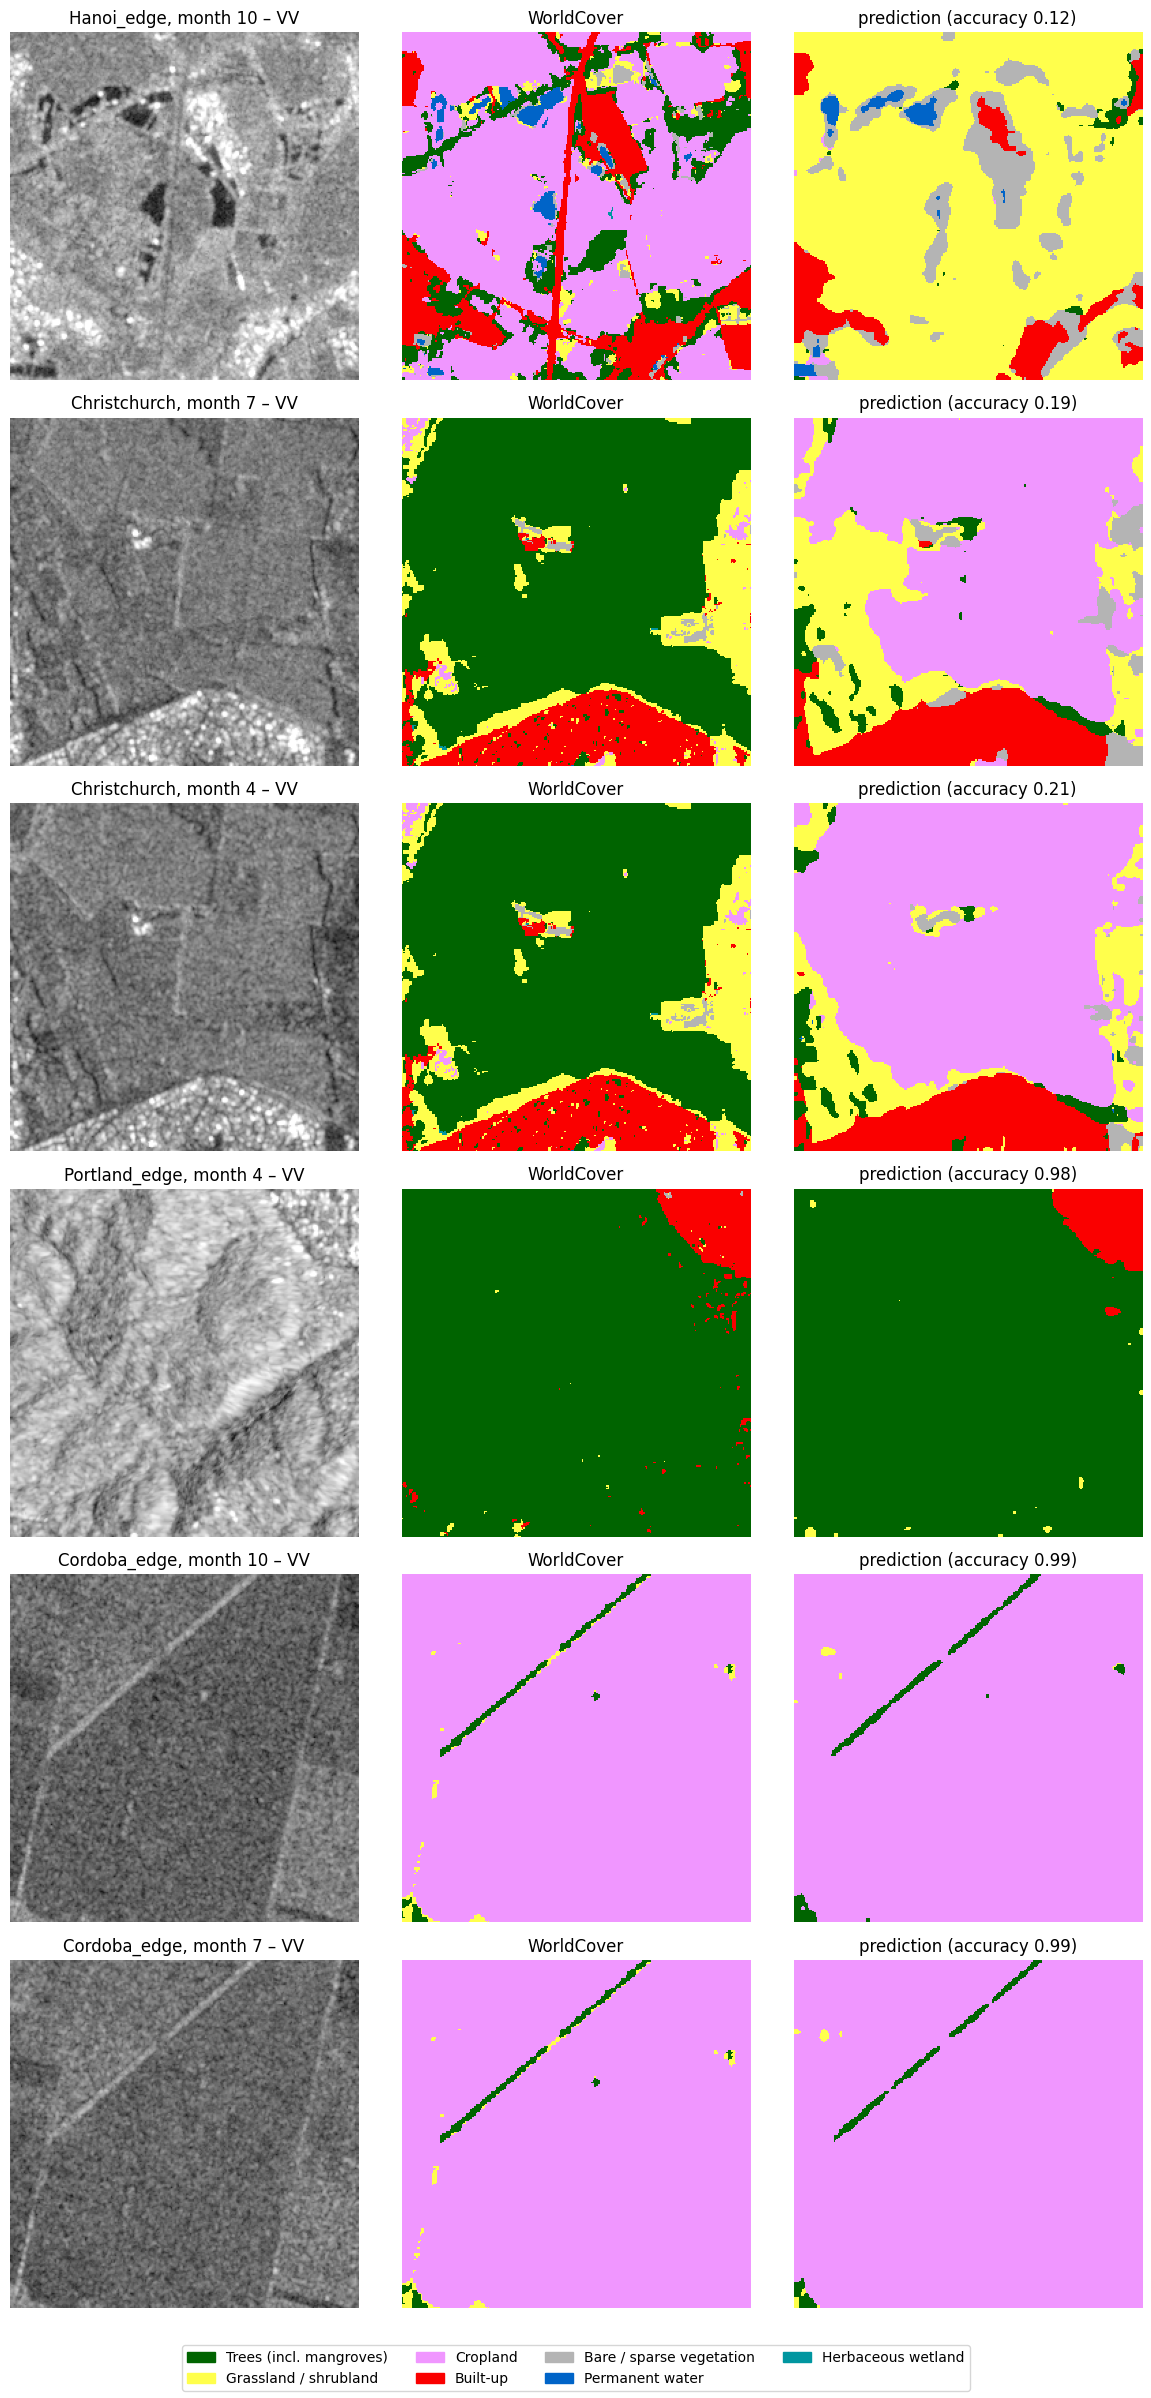

In [24]:
cmap = ListedColormap(COLORS)


def patch_accuracy(i):
    valid = data["test"]["y"][i] != IGNORE
    return (data["test"]["y"][i][valid] == test_pred[i][valid]).mean()


accuracies = np.array([patch_accuracy(i) for i in range(len(test_pred))])
order = np.argsort(accuracies)
chosen = list(order[:3]) + list(order[-3:])

fig, axes = plt.subplots(len(chosen), 3, figsize=(12, 4 * len(chosen)))
for row, i in enumerate(chosen):
    area, continent, month, r, c = test_meta[i]
    axes[row, 0].imshow(data["test"]["x"][i][..., 0].astype(np.float32), cmap="gray", vmin=-25, vmax=0)
    axes[row, 0].set_title(f"{area}, month {month} – VV")
    axes[row, 1].imshow(np.ma.masked_equal(data["test"]["y"][i], IGNORE), cmap=cmap,
                        vmin=-0.5, vmax=N_CLASSES - 0.5, interpolation="nearest")
    axes[row, 1].set_title("WorldCover")
    axes[row, 2].imshow(test_pred[i], cmap=cmap, vmin=-0.5, vmax=N_CLASSES - 0.5, interpolation="nearest")
    axes[row, 2].set_title(f"prediction (accuracy {accuracies[i]:.2f})")
    for ax in axes[row]:
        ax.axis("off")
fig.legend(handles=[Patch(color=c, label=n) for c, n in zip(COLORS, CLASSES)], loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

# Save the selected model for the prototype

In [25]:
best_model = load_trained(best_name)
best_model.save(model_folder / "lulc_model.keras")
(model_folder / "model_info.json").write_text(json.dumps({
    "model": best_name,
    "round": 2,
    "classes": CLASSES,
    "colors": COLORS,
    "ignore": IGNORE,
    "patch_size": 256,
    "needs_keras_hub": best_name.startswith("segformer"),
    "validation_miou": float(results[best_name]["valid"]["miou"]),
    "test_miou": float(results[best_name]["test"]["miou"]),
    "test_oa": float(results[best_name]["test"]["oa"]),
}, indent=2))

# quick check: reload, one validation patch, probabilities sum to 1
check = keras.models.load_model(model_folder / "lulc_model.keras", compile=False)
probabilities = np.asarray(check.predict(next(iter(valid_ds))[0][:1], verbose=0))
assert probabilities.shape == (1, 256, 256, N_CLASSES)
np.testing.assert_allclose(probabilities.sum(axis=-1), 1.0, atol=1e-3)
print("saved and checked in models/round2/: lulc_model.keras, normalisation.json, model_info.json, environment.json")

saved and checked in models/round2/: lulc_model.keras, normalisation.json, model_info.json, environment.json
